### Loading Nertwork

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv(
    "../Data/CosciaRios2012_DataBase.csv"
)

#df["Code"] = df["Code"].astype(str).str.zfill(5)

df.head()



,Code,State,Year,Beltran_Leyva,Beltran_Leyva_Family,Familia,Golfo,Juarez,Sinaloa,Sinaloa_Family,Tijuana,Zetas,Otros
0,1001,1,1990,0,0,0,0,0,0,0,0,0,0
1,1001,1,1991,0,0,0,0,0,0,0,0,0,0
2,1001,1,1992,0,0,0,0,0,0,0,0,0,0
3,1001,1,1993,0,0,0,0,0,0,0,0,0,0
4,1001,1,1994,0,0,0,0,0,0,0,0,0,0


In [3]:
# df_Zetas = df[['Code', 'Year', 'Zetas']]
# df_Zetas.head()


In [4]:
import networkx as nx


edge_df = pd.read_csv("mexico_municipality_network.csv")
edge_df.head()

,source,target
0,9012,9013
1,9012,15101
2,9012,15062
3,9012,15043
4,9012,17009


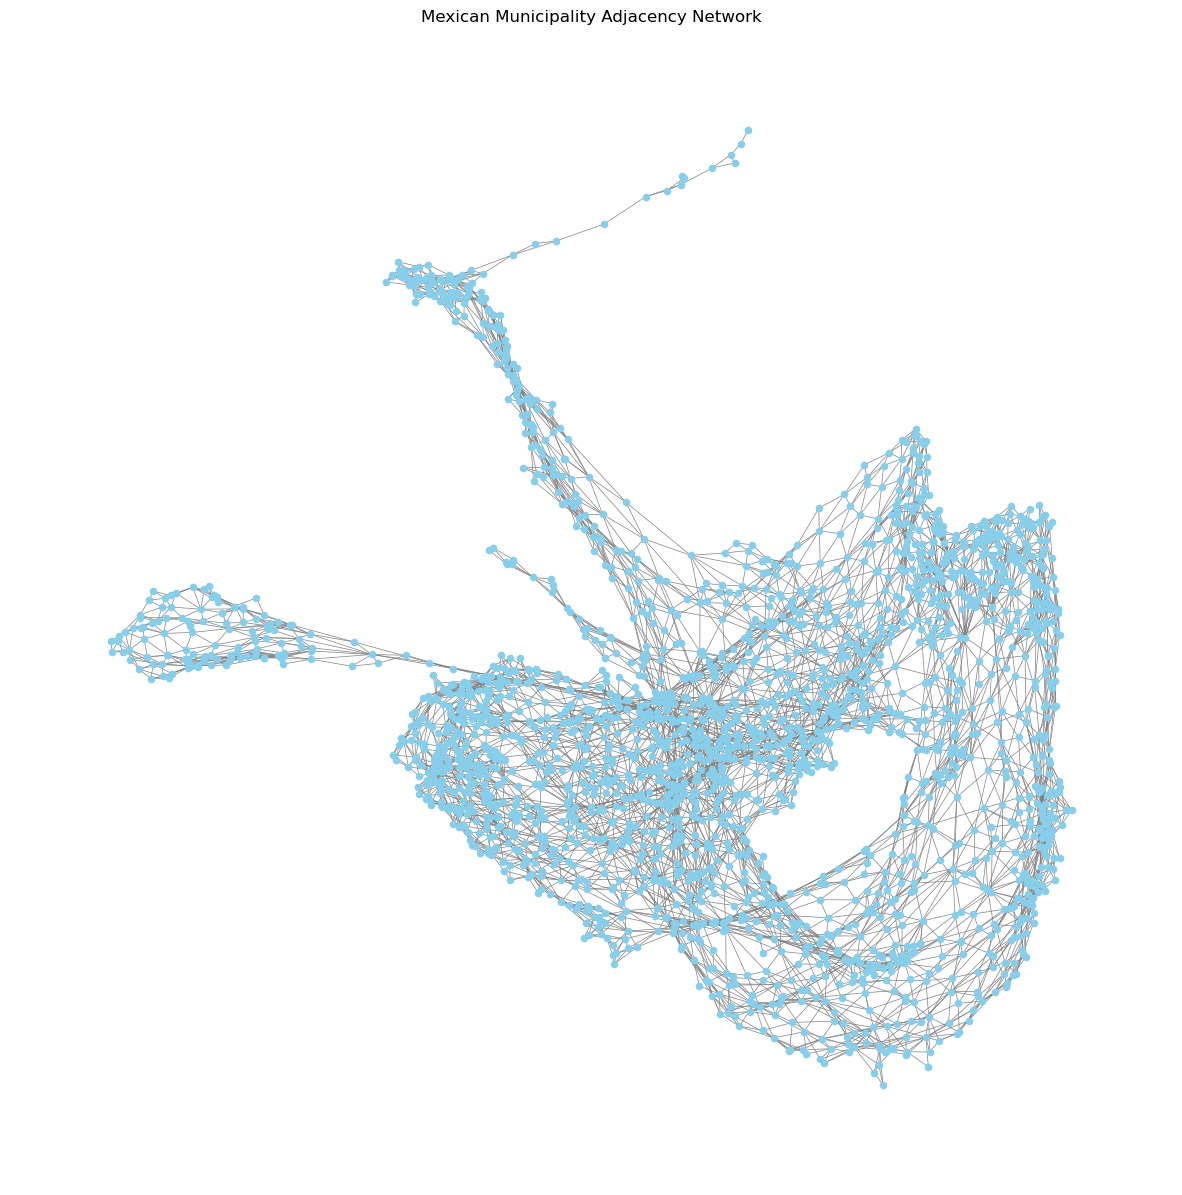

In [5]:

# Create network
G = nx.from_pandas_edgelist(
    edge_df,
    source="source",
    target="target"
)

# Plot
plt.figure(figsize=(15, 15))

pos = nx.spring_layout(G, seed=42)

nx.draw_networkx(
    G,
    pos,
    node_size=20,
    node_color="skyblue",
    edge_color="gray",
    width=0.5,
    with_labels=False
)

plt.title("Mexican Municipality Adjacency Network")
plt.axis("off")
plt.show()

In [6]:
list(G.nodes())[:5]


[9012, 9013, 15101, 15062, 15043]

In [7]:


# for year in range(1990, 2011):

#     active_munis = set(
#         df_Zetas.loc[
#             (df_Zetas["Year"] == year) &
#             (df_Zetas["Zetas"] == 1),
#             "Code"
#         ])
#     nx.set_node_attributes(
#     G,
#     {n: int(n in active_munis) for n in G.nodes()},
#     year
# )





In [8]:
# for year in range(1990, 2011):
#     active_munis = set(
#         df_Zetas.loc[
#             (df_Zetas["Year"] == year) &
#             (df_Zetas["Zetas"] == 1),
#             "Code"
#         ]
#     )

#     print(year, len(active_munis))

In [9]:
# G.nodes[9012]

In [10]:
# for year in range(1990, 2011):



#     node_colors = [
#         "red" if G.nodes[n][year] == 1 else "blue"
#         for n in G.nodes()
#     ]
#     node_sizes = [
#         25 if G.nodes[n][year] == 1 else 7
#         for n in G.nodes()
#     ]

#     plt.figure(figsize=(12,12))
#     nx.draw(
#         G,
#         pos,
#         node_color=node_colors,
#         node_size=node_sizes,
#         edge_color="gray",
#         width=0.5,
#         alpha=0.7
#     )

#     plt.title(f"Zetas Presence ({year})")
#     plt.axis("off")
#     plt.show()

KeyError: 1990

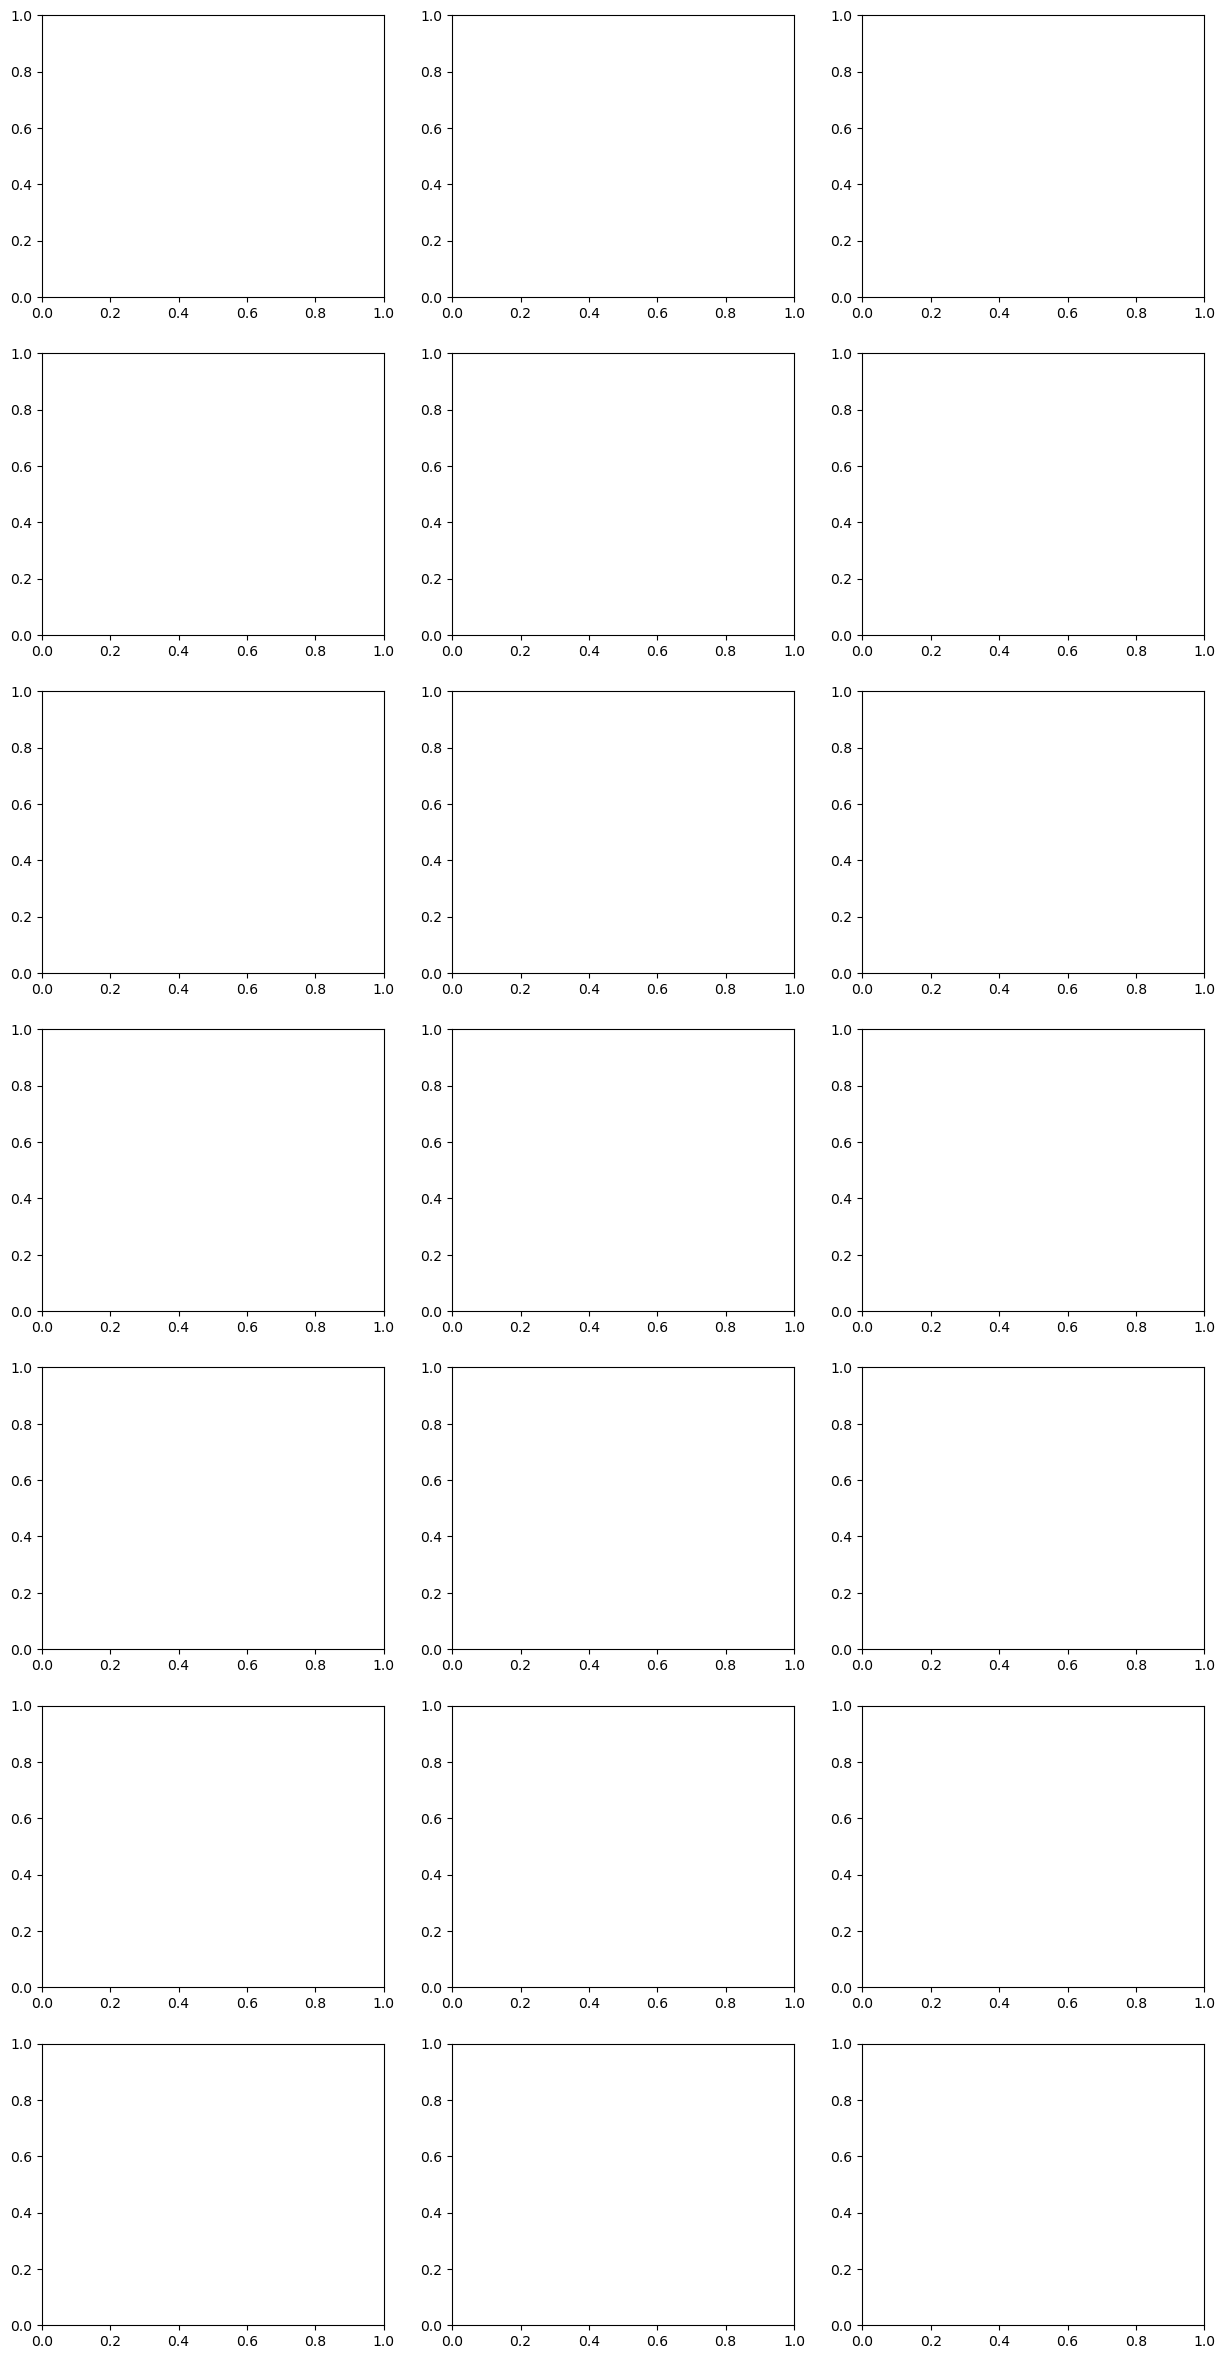

In [ ]:
# fig, axes = plt.subplots(7, 3, figsize=(15, 30))
# axes = axes.flatten()

# for i, year in enumerate(range(1990, 2011)):

#     node_colors = [
#         "red" if G.nodes[n][year] == 1 else "blue"
#         for n in G.nodes()
#     ]

#     node_sizes = [
#         7 if G.nodes[n][year] == 1 else 1
#         for n in G.nodes()
#     ]

#     nx.draw(
#         G,
#         pos,
#         ax=axes[i],
#         node_color=node_colors,
#         node_size=node_sizes,
#         edge_color="lightgray",
#         width=0.5,
#         alpha=0.4,
#         with_labels=False
#     )

#     axes[i].set_title(year)
#     axes[i].axis("off")

# plt.tight_layout()
# plt.show()

# Machine learning

In [12]:
## for 4 cartels:

df_4 = df[['Code', 'Year', 'Zetas', 'Sinaloa', 'Otros', 'Familia']]

G_4 = nx.from_pandas_edgelist(
    edge_df,
    source="source",
    target="target"
)

families = ['Zetas', 'Sinaloa', 'Otros', 'Familia']


for year in range(1990, 2011):
    for municipality in G_4.nodes():

        family_presence = {
            family: int(
                municipality in set(
                    df_4.loc[
                        (df_4["Year"] == year) &
                        (df_4[family] == 1),
                        "Code"
                    ]
                )
            )
            for family in families
        }

        family_presence["total_families"] = sum(family_presence.values())

        G_4.nodes[municipality][year] = family_presence


In [16]:
municipality_chosen = 9012
year_chosen = 2005
G_4.nodes[municipality_chosen][year_chosen]

{'Zetas': 1, 'Sinaloa': 0, 'Otros': 0, 'Familia': 0, 'total_families': 1}

C:\Users\Dumitru\AppData\Local\Temp\ipykernel_8080\1332662936.py:31: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


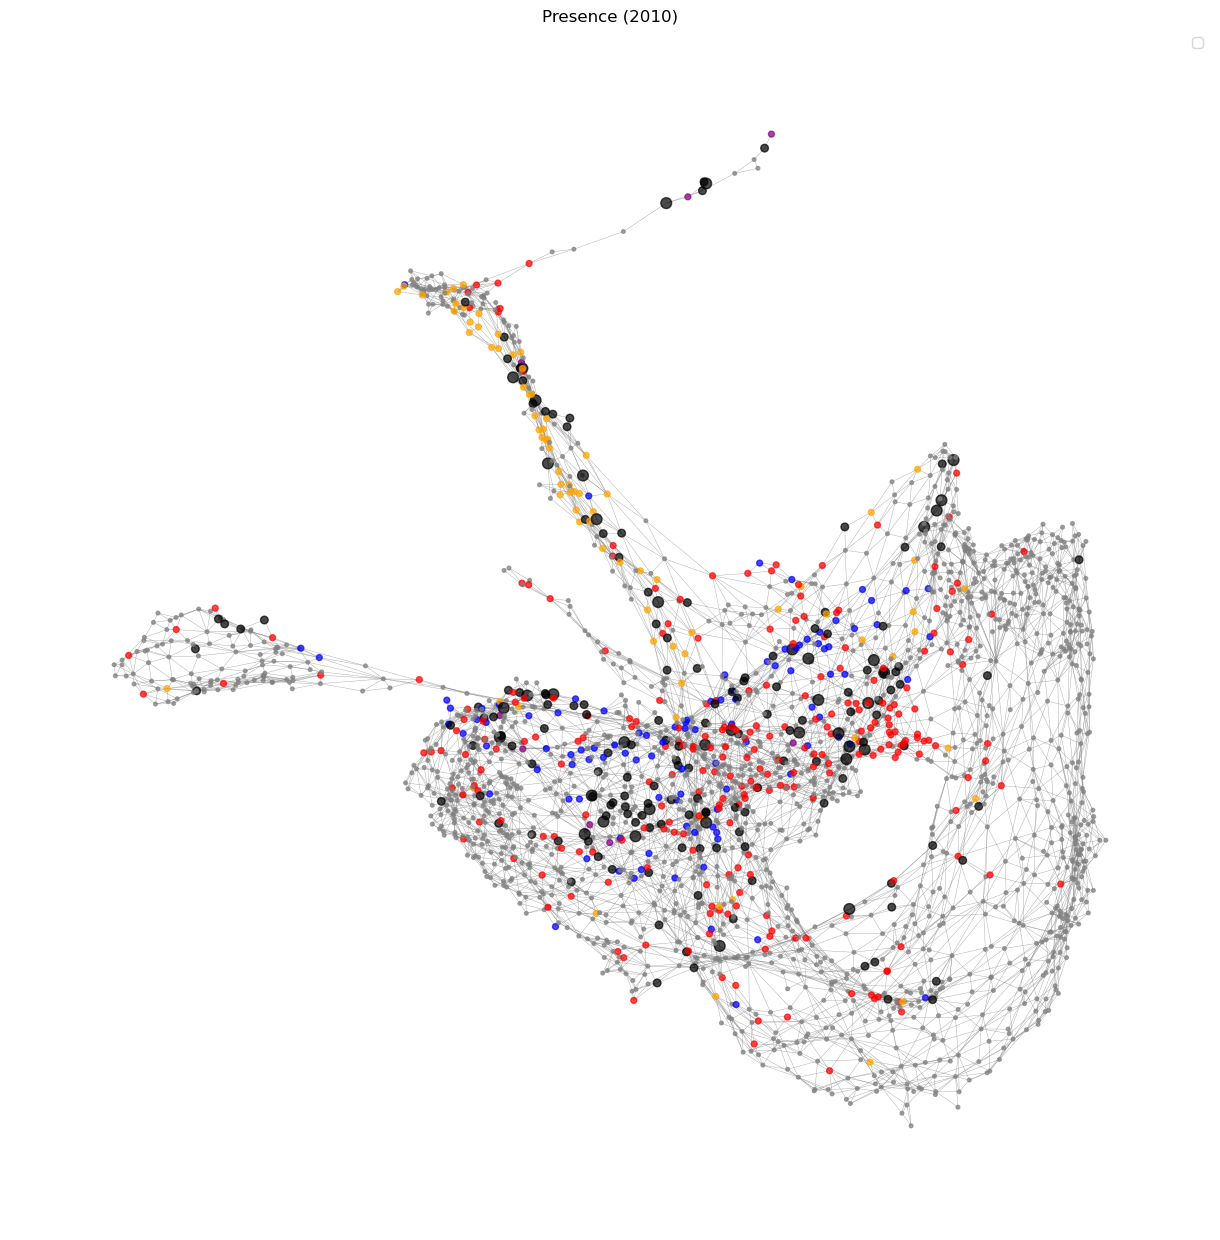

In [15]:
#for year in range(1990, 2011):

year = 2010

node_colors = [
    'black' if G_4.nodes[n][year]['total_families'] > 1 else
    "red" if G_4.nodes[n][year]['Zetas'] == 1 else
    "orange" if G_4.nodes[n][year]['Sinaloa'] == 1 else
    "purple" if G_4.nodes[n][year]['Otros'] == 1 else
    "blue" if G_4.nodes[n][year]['Familia'] == 1 else   "gray" 
    for n in G_4.nodes()
]
node_sizes = [
    60 if G_4.nodes[n][year]['total_families'] > 2 else
    30 if G_4.nodes[n][year]['total_families'] == 2 else
    18 if G_4.nodes[n][year]['total_families'] == 1 else 7
 
    for n in G_4.nodes()
]

plt.figure(figsize=(12,12))
nx.draw(
    G_4,
    pos,
    node_color=node_colors,
    node_size=node_sizes,
    edge_color="gray",
    width=0.3,
    alpha=0.7
)
plt.legend()
plt.title(f"Presence ({year})")
plt.axis("off")
plt.show()

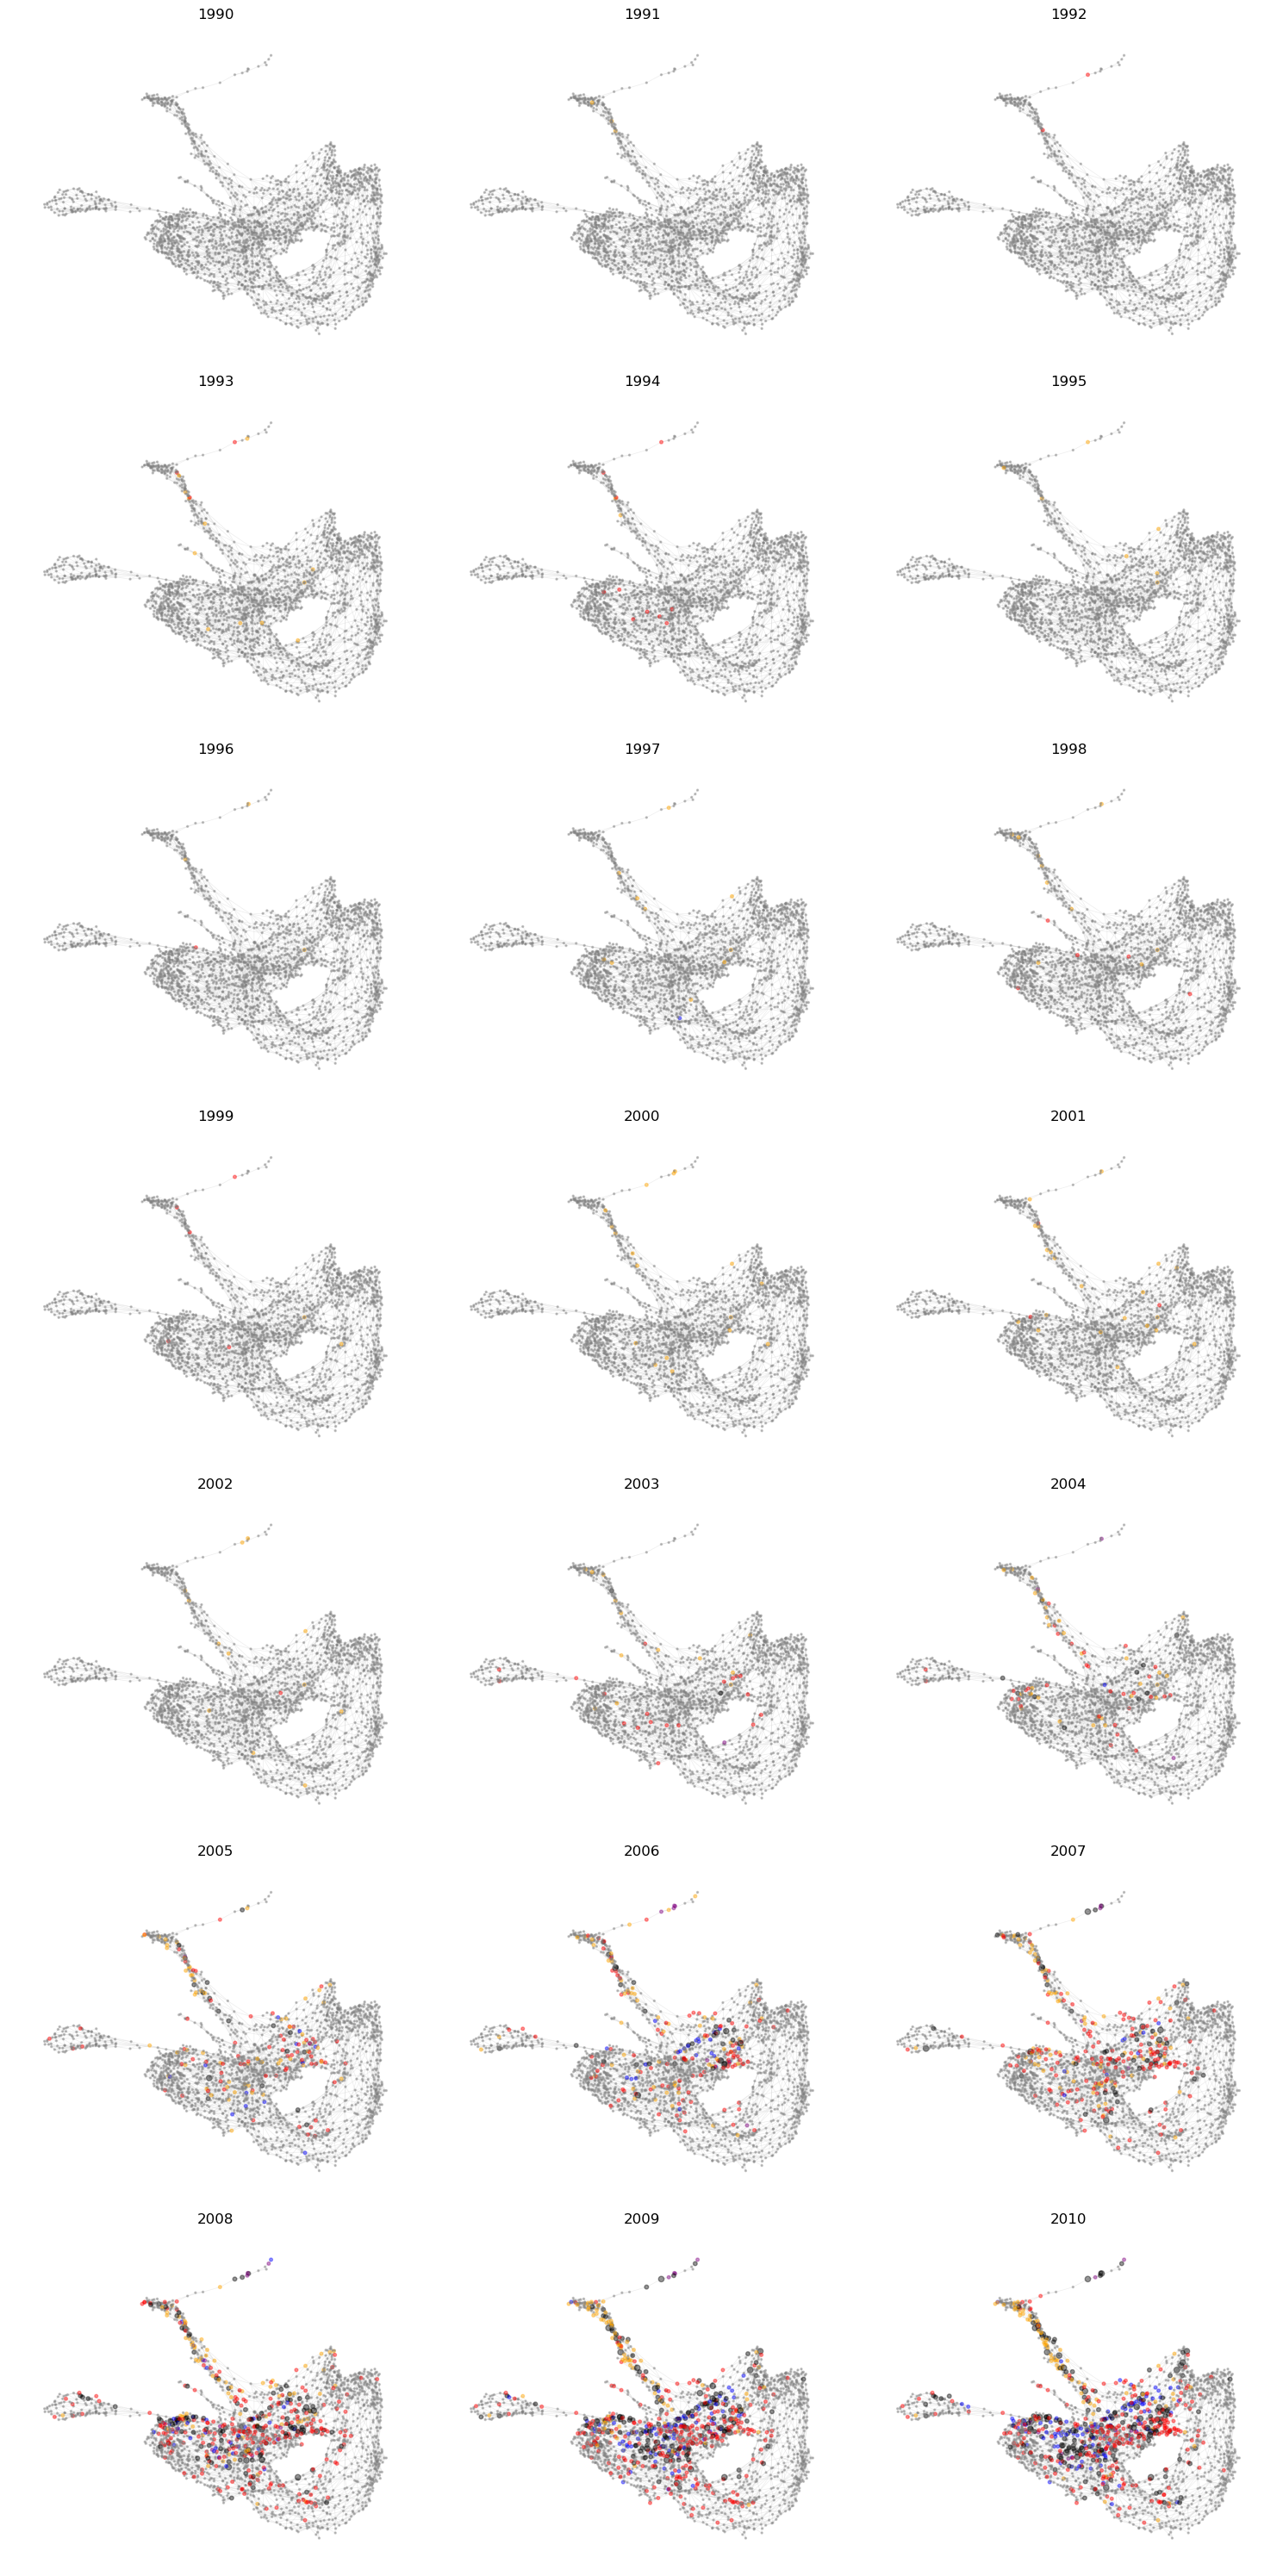

In [ ]:
fig, axes = plt.subplots(7, 3, figsize=(15, 30))
axes = axes.flatten()

for i, year in enumerate(range(1990, 2011)):

    node_colors = [
        'black' if G_4.nodes[n][year]['total_families'] > 1 else
        "red" if G_4.nodes[n][year]['Zetas'] == 1 else
        "orange" if G_4.nodes[n][year]['Sinaloa'] == 1 else
        "purple" if G_4.nodes[n][year]['Otros'] == 1 else
        "blue" if G_4.nodes[n][year]['Familia'] == 1 else   "gray" 
        for n in G_4.nodes()
    ]
    node_sizes = [
        21 if G_4.nodes[n][year]['total_families'] > 2 else
        11 if G_4.nodes[n][year]['total_families'] == 2 else
        7 if G_4.nodes[n][year]['total_families'] == 1 else 2
    
        for n in G_4.nodes()
    ]

    nx.draw(
        G,
        pos,
        ax=axes[i],
        node_color=node_colors,
        node_size=node_sizes,
        edge_color="lightgray",
        width=0.5,
        alpha=0.4,
        with_labels=False
    )

    axes[i].set_title(year)
    axes[i].axis("off")

plt.tight_layout()
plt.show()

Features to take into account:

1) direct neighbours of infected points
2) 2nd direct neighbours of infected points